In [33]:
import os
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import json
import cv2
from tqdm import tqdm

In [2]:
base_path = "/mnt/pg-fs01/Current/DB/ObjectDetectionV3"
df = pd.read_csv(os.path.join(base_path, "images.csv"))

names = df["name"].values
names = np.unique(names)
names.shape

(970,)

In [3]:
names_sem_sim = np.load("names_semantic_similrity.npy", allow_pickle=True)
names_img_sim = np.load("names_image_similrity.npy", allow_pickle=True)

distances_sem_sim = np.load("distances_semantic_similrity.npy", allow_pickle=True)
distances_img_sim = np.load("distances_image_similrity.npy", allow_pickle=True)

all(names_sem_sim == names_img_sim), all(names == names_sem_sim)

(True, True)

In [4]:
with open("goups.json", "r") as f:
    groups = json.load(f)

In [5]:
pearsonr(distances_sem_sim.flatten(), distances_img_sim.flatten())

PearsonRResult(statistic=0.5449061356406527, pvalue=0.0)

In [6]:
np.min(distances_sem_sim), np.max(distances_sem_sim), np.mean(distances_sem_sim), np.std(distances_sem_sim)

(0.045809462666511536,
 1.000000238418579,
 0.5405348434816868,
 0.1833451679373025)

In [7]:
np.min(distances_img_sim), np.max(distances_img_sim), np.mean(distances_img_sim), np.std(distances_img_sim)

(-0.05559932813048363,
 1.000000238418579,
 0.26459803269638976,
 0.14105491647428028)

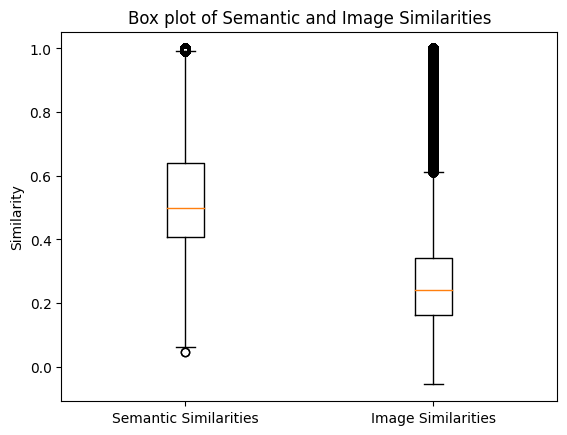

In [8]:
plt.boxplot([distances_sem_sim.flatten(), distances_img_sim.flatten()], labels=['Semantic Similarities', 'Image Similarities'])
plt.title('Box plot of Semantic and Image Similarities')
plt.ylabel('Similarity')
plt.show()

In [9]:
groups

{'2017_06': ['2017_06_21_DL_SL_Farnel02_H270_15m_1495096750_f_00312_02122-11_1985.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495096750_f_02640_04440-9_1260.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495097650_f_02424_04224-10_105.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495097650_f_02424_04224-9_2735.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495110256_f_00000_01800-10_2056.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495110256_f_00000_01800-12_3404.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495111158_f_00000_01800-11_689.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495111158_f_01800_03600-11_3418.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495111158_f_06504_08304-14_106.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495115760_f_00000_01800-11_280.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495115760_f_03672_05472-12_97.jpg',
  '2017_06_21_DL_SL_Farnel02_H270_15m_1495115760_f_05472_07272-11_2422.jpg'],
 '2017_07': ['2017_07_13_DL_SL_Old_Lunch_Room02_H270_60m_1495098353_f_33

In [10]:
tst_group_names = [
    'Cam2_H256_Menivim_cs',
    'Cam2_H255',
    'Cam2_H256_Menivim_fin ance',
    'Cam2_H256_Menivim_financ e',
    'Cam2_H256_Menivim_finance',
    'Cam2_H256_menivimks',
    'Cam3_H245_discount',
]

In [11]:
groups[tst_group_names[0]]

['Cam2_H256_Menivim_cs_1.png',
 'Cam2_H256_Menivim_cs_2.png',
 'Cam2_H256_Menivim_cs_3.png',
 'Cam2_H256_Menivim_cs_4.png']

In [12]:
# Use np.where to find the indices where mask is True
indices0 = np.where(np.isin(names, groups[tst_group_names[2]]))[0]
indices1 = np.where(np.isin(names, groups[tst_group_names[3]]))[0]

print(np.mean(distances_img_sim[indices0, indices0]), np.mean(distances_img_sim[indices1, indices1]), np.mean(distances_img_sim[indices0, indices1]))
print(np.mean(distances_sem_sim[indices0, indices0]), np.mean(distances_sem_sim[indices1, indices1]), np.mean(distances_sem_sim[indices0, indices1]))

1.0 1.0 0.8689867258071899
1.0000001192092896 1.0000001192092896 0.9085314273834229


In [13]:
def get_elements(x, row_indices, col_indices):
    return np.array([x[i, j] for i in row_indices for j in col_indices])

for i in range(len(tst_group_names) - 1):
    for j in range(i + 1, len(tst_group_names)):
        indices0 = np.where(np.isin(names, groups[tst_group_names[i]]))[0]
        indices1 = np.where(np.isin(names, groups[tst_group_names[j]]))[0]

        print(tst_group_names[i], tst_group_names[j])
        print(
            np.mean(get_elements(distances_img_sim, indices0, indices0)),
            np.mean(get_elements(distances_img_sim, indices1, indices1)),
            np.mean(get_elements(distances_img_sim, indices0, indices1)),
            np.max(get_elements(distances_img_sim, indices0, indices1))
        )
        # print(
        #     np.mean(get_elements(distances_sem_sim, indices0, indices0)),
        #     np.mean(get_elements(distances_sem_sim, indices1, indices1)),
        #     np.mean(get_elements(distances_sem_sim, indices0, indices1))
        # )
        print("=" * 25)
    print()

Cam2_H256_Menivim_cs Cam2_H255
0.8846988677978516 0.6617974303662777 0.3420389575883746 0.4725978970527649
Cam2_H256_Menivim_cs Cam2_H256_Menivim_fin ance
0.8846988677978516 1.0 0.4763275012373924 0.4931274652481079
Cam2_H256_Menivim_cs Cam2_H256_Menivim_financ e
0.8846988677978516 1.0 0.5139472261071205 0.5307797193527222
Cam2_H256_Menivim_cs Cam2_H256_Menivim_finance
0.8846988677978516 0.8382263481616974 0.5265950101117293 0.6337243914604187
Cam2_H256_Menivim_cs Cam2_H256_menivimks
0.8846988677978516 0.5665344889793131 0.5895262056340774 0.9855989217758179
Cam2_H256_Menivim_cs Cam3_H245_discount
0.8846988677978516 0.6853562173370488 0.3205625018612905 0.4357597827911377

Cam2_H255 Cam2_H256_Menivim_fin ance
0.6617974303662777 1.0 0.2355754267424345 0.3265942335128784
Cam2_H255 Cam2_H256_Menivim_financ e
0.6617974303662777 1.0 0.2418057791888714 0.35174885392189026
Cam2_H255 Cam2_H256_Menivim_finance
0.6617974303662777 0.8382263481616974 0.27564923173437517 0.43459972739219666
Cam2_H2

In [14]:
def draw_group(group_items: list, group_name: str, n: int = 3):
    if len(group_items) < n:
        subgroup = group_items
    else:
        subgroup = np.random.choice(group_items, n, replace=False)
    plt.figure(figsize=(15, 4))
    plt.suptitle(group_name, fontsize=14)
    for i, item in enumerate(subgroup):
        row = df[df["name"] == item]
        pth = os.path.join(base_path, row["batch"].iloc[0], row["folder"].iloc[0], item)
        img = cv2.cvtColor(cv2.imread(pth), cv2.COLOR_BGR2RGB)
        plt.subplot(1, len(subgroup), i + 1)
        plt.imshow(img)
        plt.title(item)

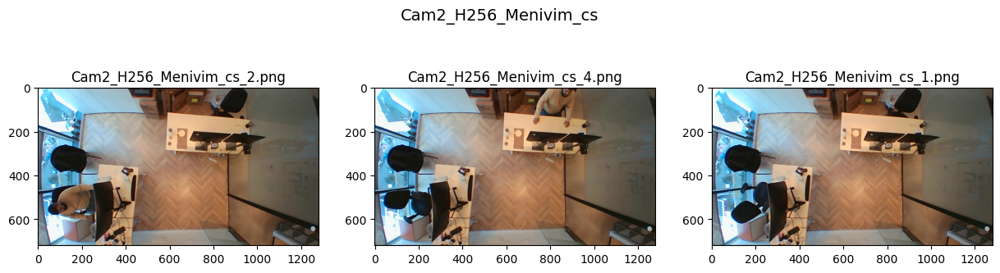

In [15]:
name = "Cam2_H256_Menivim_cs"
draw_group(groups[name], name)

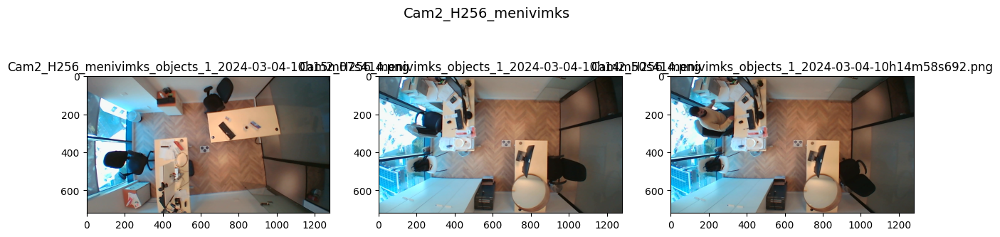

In [16]:
name = "Cam2_H256_menivimks"
draw_group(groups[name], name)

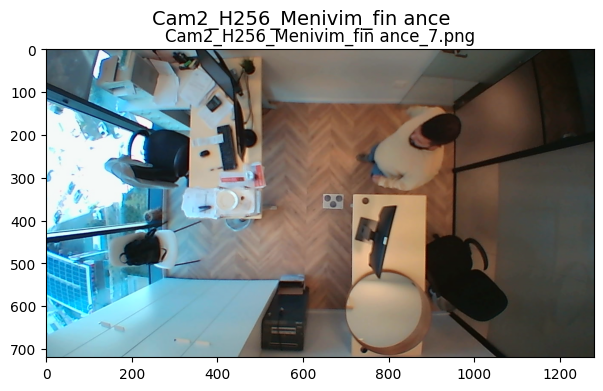

In [17]:
name = "Cam2_H256_Menivim_fin ance"
draw_group(groups[name], name)

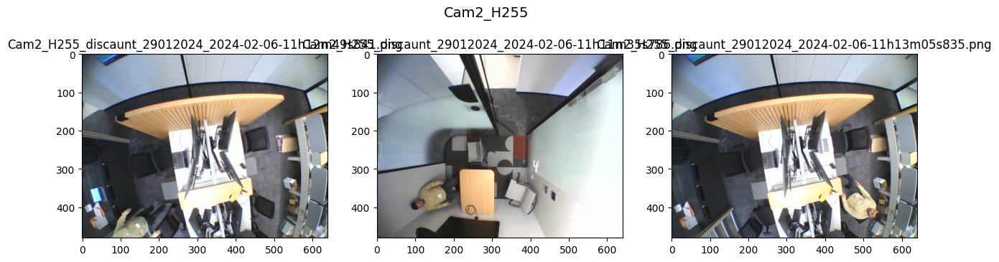

In [18]:
name = "Cam2_H255"
draw_group(groups[name], name)

In [19]:
def dfs(node, visited, M, component):
    visited[node] = True
    component.append(node)
    for i, val in enumerate(M[node]):
        if val == 1 and not visited[i]:
            dfs(i, visited, M, component)

def find_connected_components(M):
    visited = [False] * len(M)
    components = []
    for i in range(len(M)):
        if not visited[i]:
            component = []
            dfs(i, visited, M, component)
            components.append(component)
    return components

# Assuming you have a 2D numpy array
M = np.array([[0, 1, 0, 0], [1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0]])

components = find_connected_components(M)
print(components)  # Outputs: [[0, 1, 2, 3]]

# Example usage:
matrix = np.array([[1, 1, 0, 0],
                   [1, 1, 0, 0],
                   [0, 0, 1, 1],
                   [0, 0, 1, 1]])

connected_components = find_connected_components(matrix)
print(connected_components)

[[0, 1, 2, 3]]
[[0, 1], [2, 3]]


In [34]:
def get_elements(x, row_indices, col_indices):
    return np.array([x[i, j] for i in row_indices for j in col_indices])


def compute_group_similarities(group_names: dict) -> tuple:
    avg_inner_group_similarities = []
    for i in tqdm(range(len(group_names)), desc="Computing inner group similarities"):
        indices0 = np.where(np.isin(names, groups[group_names[i]]))[0]
        avg_inner_group_similarities.append(np.mean(get_elements(distances_img_sim, indices0, indices0)))

    avg_outer_goup_similarities = np.zeros((len(group_names), len(group_names)))
    max_outer_group_similarities = np.zeros((len(group_names), len(group_names)))
    for i in tqdm(range(len(group_names) - 1), desc="Computing outer group similarities"):
        for j in range(i + 1, len(group_names)):
            indices0 = np.where(np.isin(names, groups[group_names[i]]))[0]
            indices1 = np.where(np.isin(names, groups[group_names[j]]))[0]

            sims = get_elements(distances_img_sim, indices0, indices1)
            avg_outer_goup_similarities[i, j] = avg_outer_goup_similarities[j, i] = np.mean(sims)
            max_outer_group_similarities[i, j] = max_outer_group_similarities[j, i] = np.max(sims)

    return avg_inner_group_similarities, avg_outer_goup_similarities, max_outer_group_similarities

In [35]:
avg_inner_group_similarities, avg_outer_goup_similarities, max_outer_group_similarities = compute_group_similarities(tst_group_names)

Computing outer group similarities: 100%|██████████| 6/6 [00:00<00:00, 168.28it/s]


In [36]:
tst_group_names

['Cam2_H256_Menivim_cs',
 'Cam2_H255',
 'Cam2_H256_Menivim_fin ance',
 'Cam2_H256_Menivim_financ e',
 'Cam2_H256_Menivim_finance',
 'Cam2_H256_menivimks',
 'Cam3_H245_discount']

In [37]:
np.round(avg_inner_group_similarities, 3)

array([0.885, 0.662, 1.   , 1.   , 0.838, 0.567, 0.685])

In [38]:
np.round(avg_outer_goup_similarities, 3)

array([[0.   , 0.342, 0.476, 0.514, 0.527, 0.59 , 0.321],
       [0.342, 0.   , 0.236, 0.242, 0.276, 0.321, 0.411],
       [0.476, 0.236, 0.   , 0.869, 0.768, 0.542, 0.227],
       [0.514, 0.242, 0.869, 0.   , 0.819, 0.567, 0.241],
       [0.527, 0.276, 0.768, 0.819, 0.   , 0.585, 0.276],
       [0.59 , 0.321, 0.542, 0.567, 0.585, 0.   , 0.286],
       [0.321, 0.411, 0.227, 0.241, 0.276, 0.286, 0.   ]])

In [39]:
conn_mtx = (avg_outer_goup_similarities >= 0.5).astype(int)
conn_mtx

array([[0, 0, 0, 1, 1, 1, 0],
       [0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 1, 1, 0],
       [1, 0, 1, 0, 1, 1, 0],
       [1, 0, 1, 1, 0, 1, 0],
       [1, 0, 1, 1, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 0]])

In [40]:
connected_components = find_connected_components(conn_mtx)
print(connected_components)

[[0, 3, 2, 4, 5], [1], [6]]


In [42]:
avg_inner_group_similarities, avg_outer_goup_similarities, max_outer_group_similarities = \
    compute_group_similarities(list(groups.keys()))

Computing outer group similarities: 100%|██████████| 119/119 [00:02<00:00, 42.43it/s]


In [86]:
# 0.55 >= good result
# 0.6 - ideal middle
# 65 - not so good
th = 0.6
conn_mtx = (avg_outer_goup_similarities >= th).astype(int)
connected_components = find_connected_components(conn_mtx)

with open(f"connected_components_{th}.json", "w") as f:
    json.dump(connected_components, f)

print(len(connected_components))

connected_components = sorted(connected_components, key=lambda x: len(x), reverse=True)

96


In [87]:
connected_components[:3]

[[15, 57, 24, 53, 52, 54, 56, 55], [22, 28, 40, 47], [37, 38, 45, 44]]

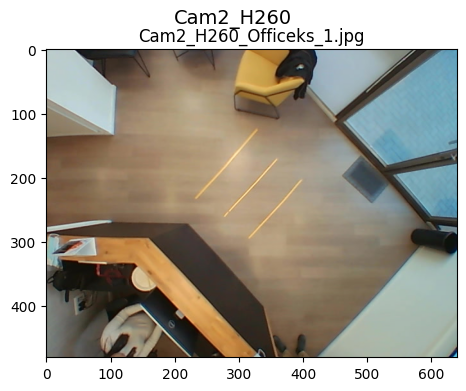

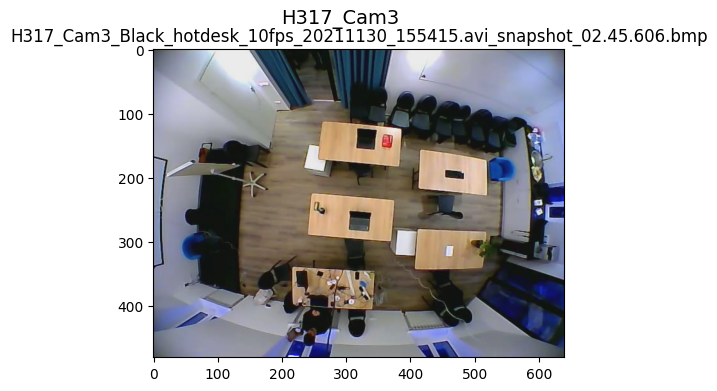

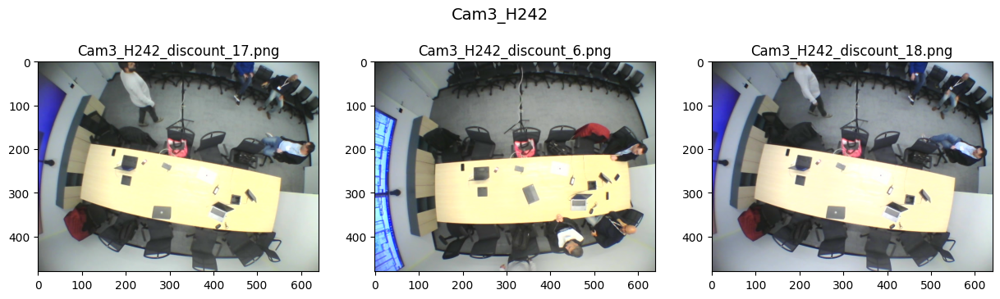

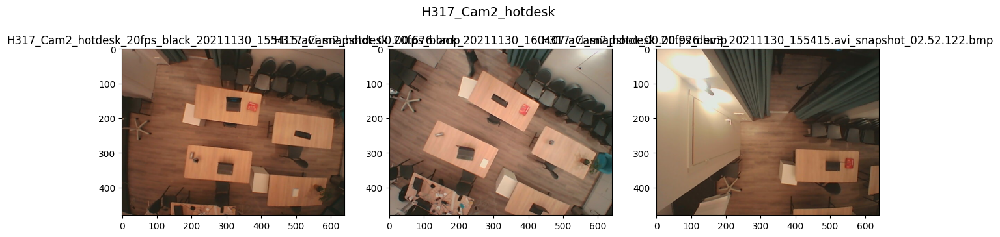

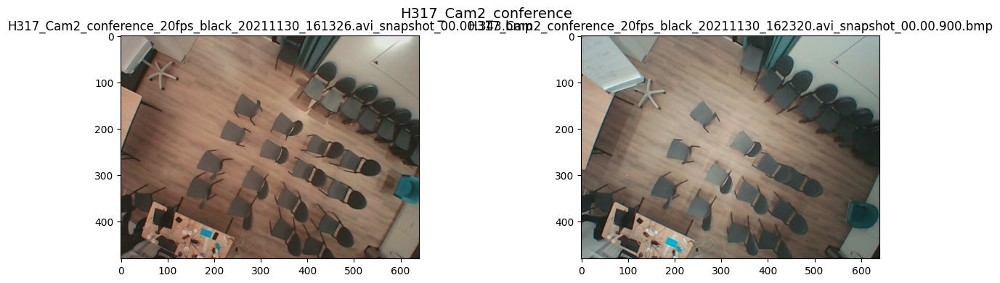

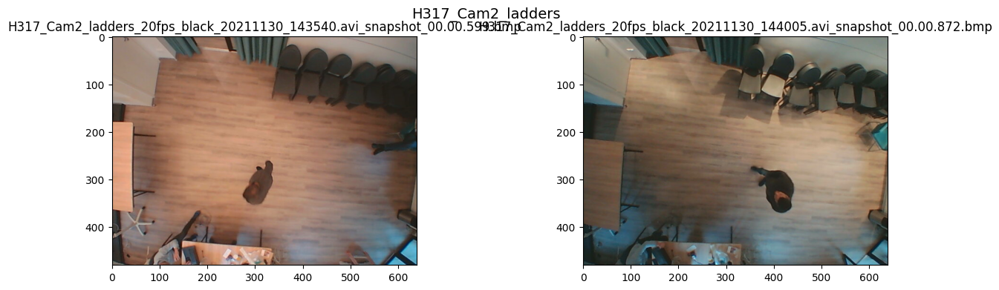

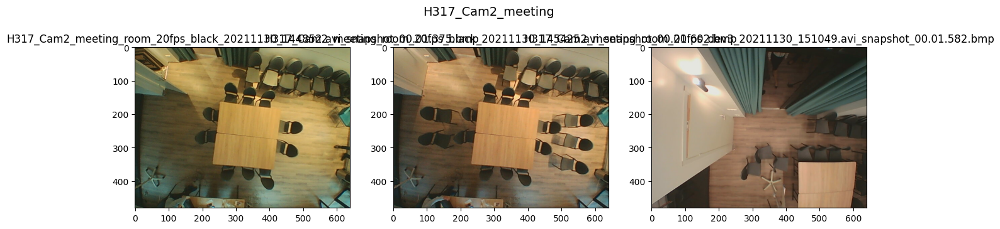

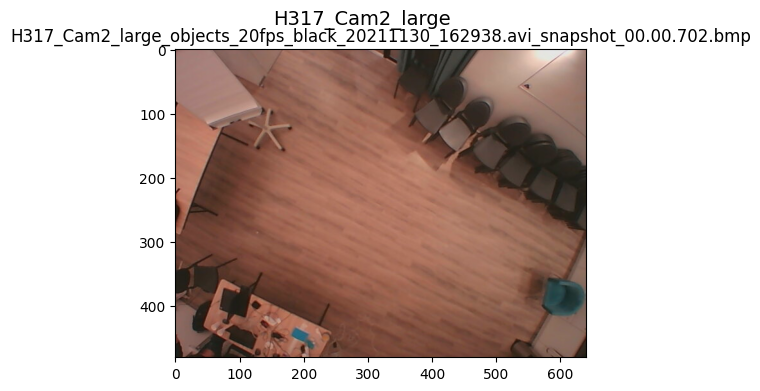

In [88]:
for name in np.array(list(groups.keys()))[connected_components[0]]:
    draw_group(groups[name], name)

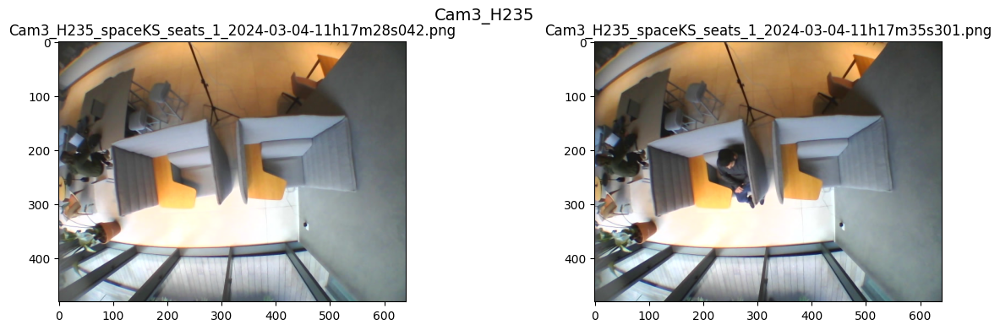

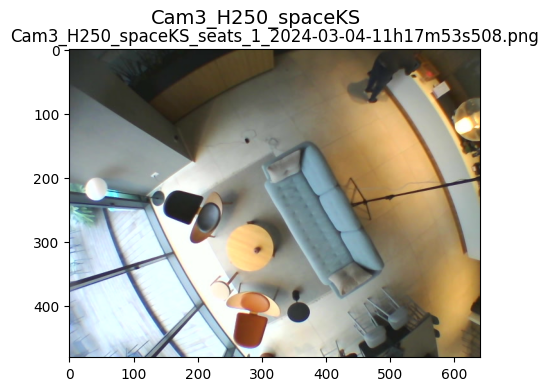

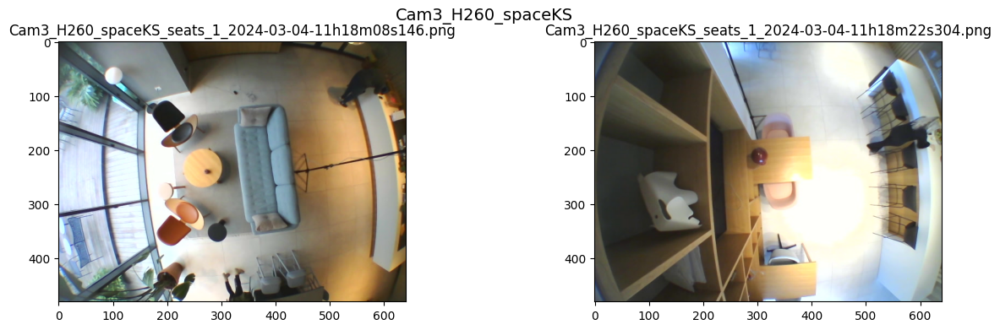

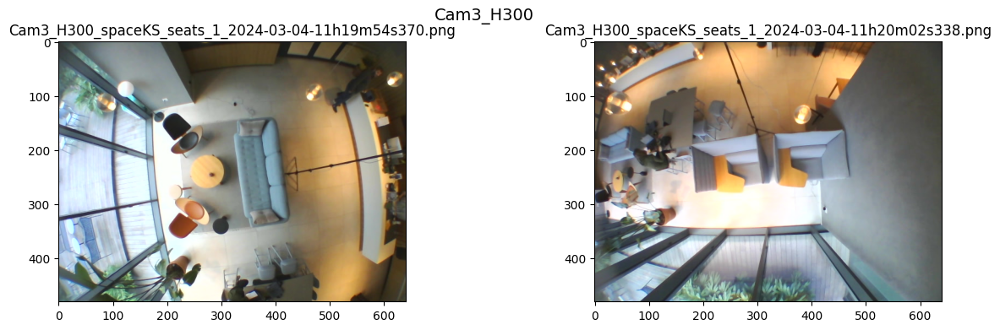

In [89]:
for name in np.array(list(groups.keys()))[connected_components[1]]:
    draw_group(groups[name], name)

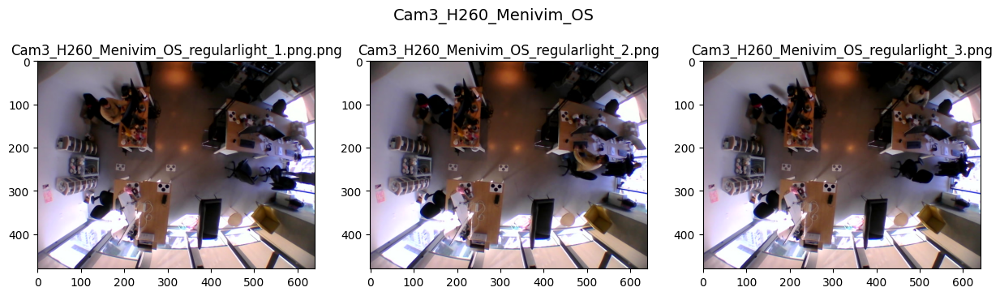

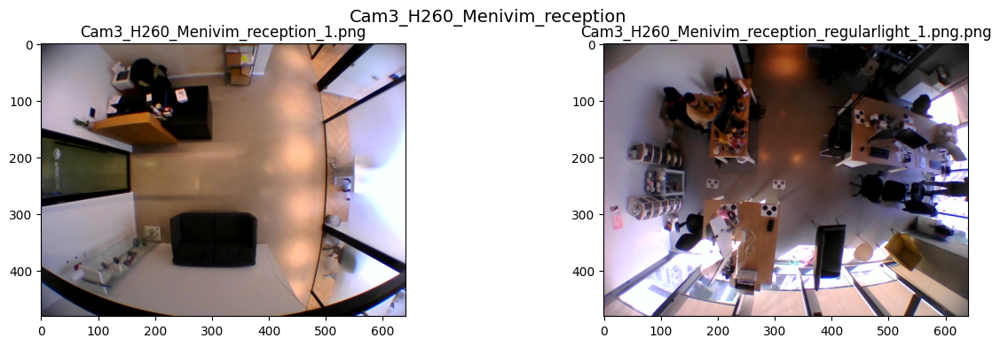

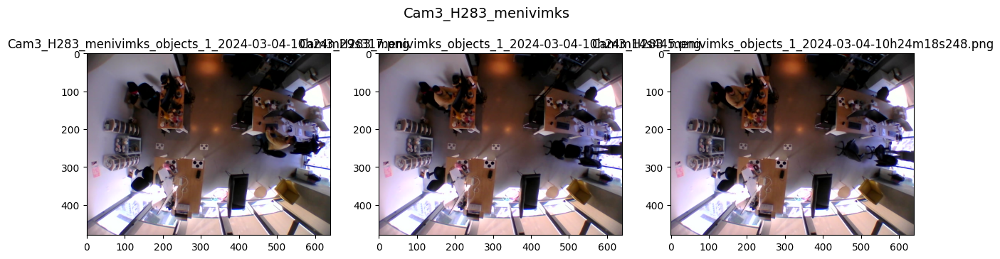

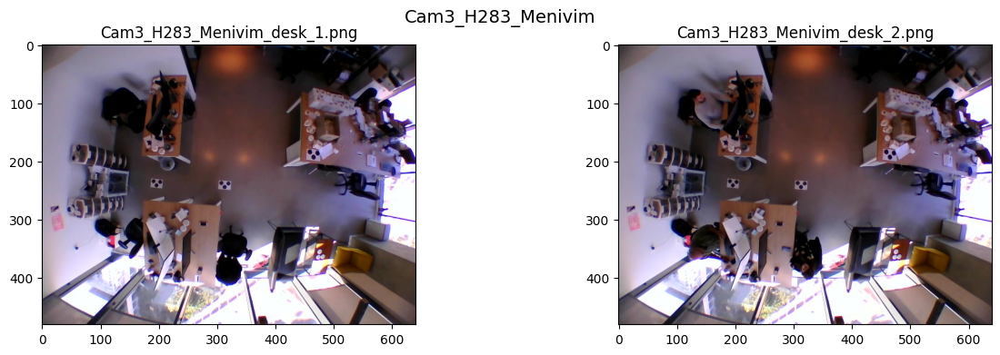

In [90]:
for name in np.array(list(groups.keys()))[connected_components[2]]:
    draw_group(groups[name], name)

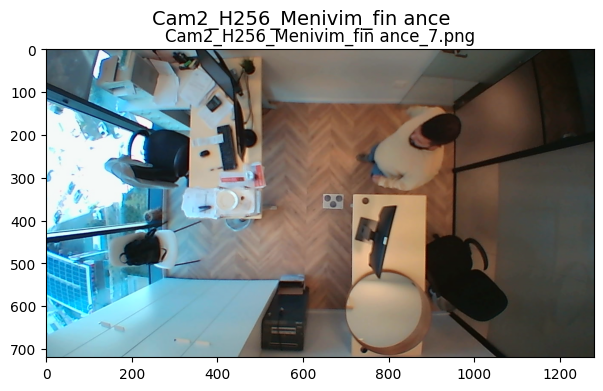

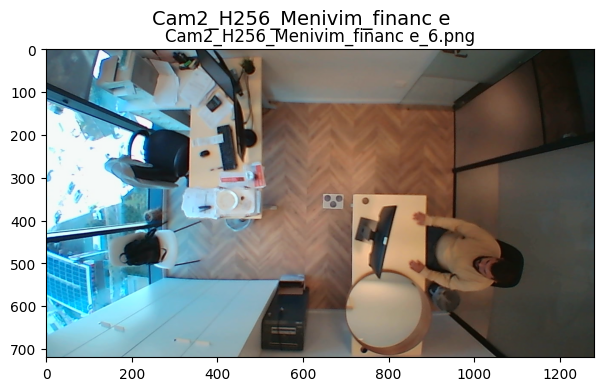

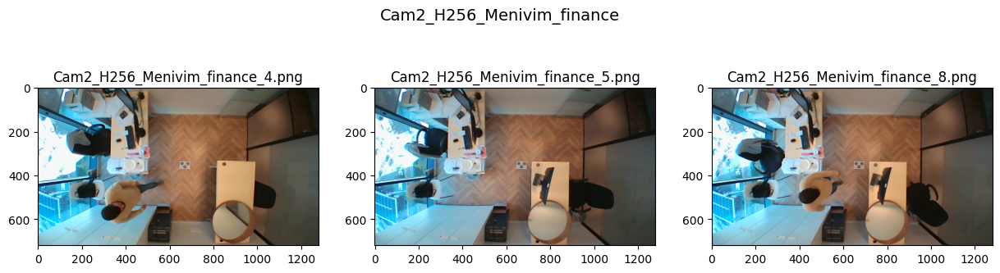

In [91]:
for name in np.array(list(groups.keys()))[connected_components[3]]:
    draw_group(groups[name], name)

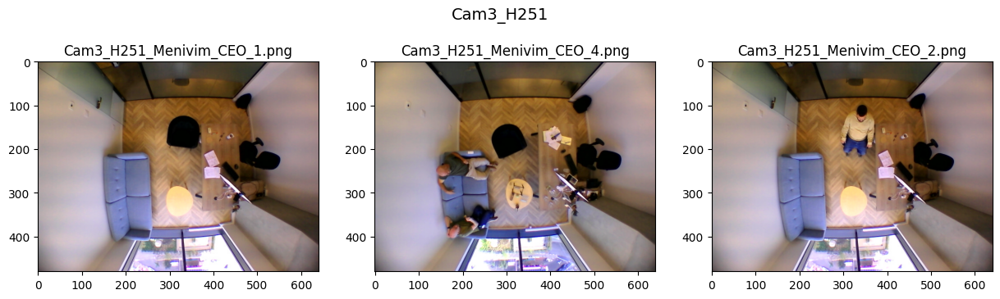

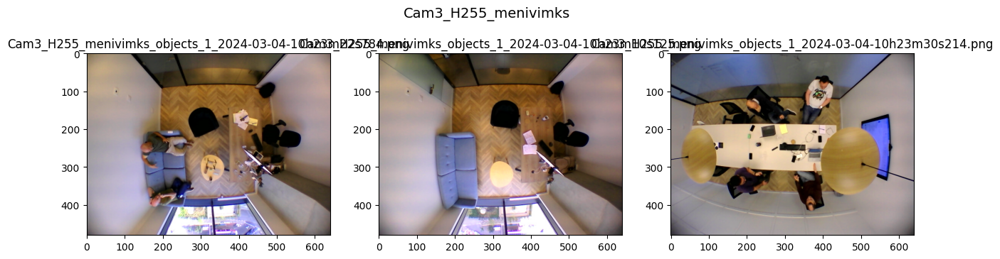

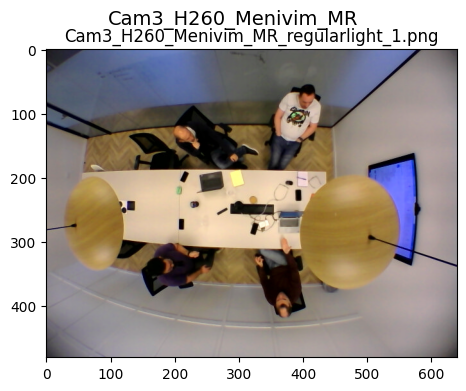

In [92]:
for name in np.array(list(groups.keys()))[connected_components[4]]:
    draw_group(groups[name], name)

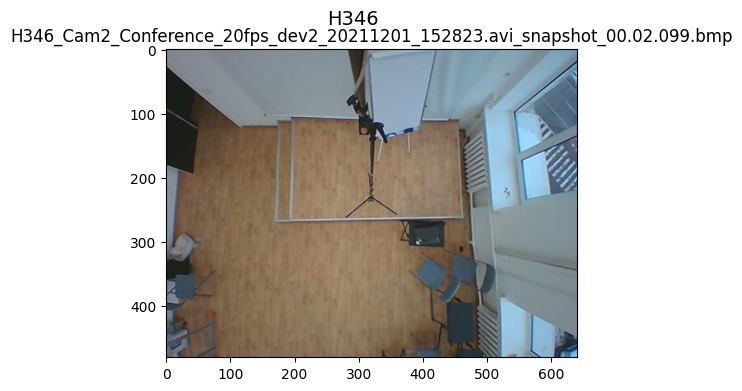

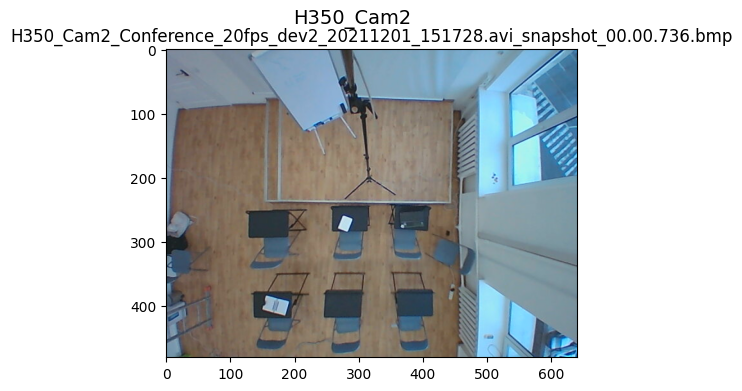

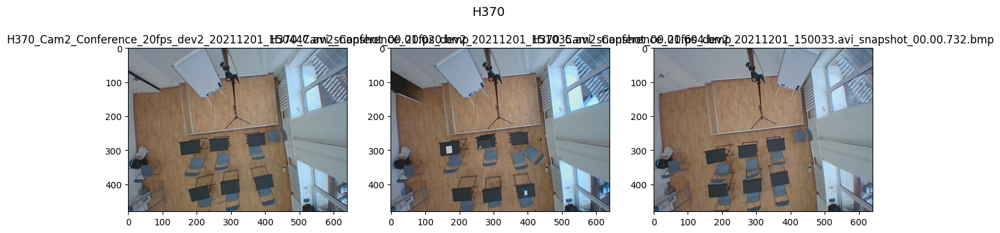

In [93]:
for name in np.array(list(groups.keys()))[connected_components[5]]:
    draw_group(groups[name], name)

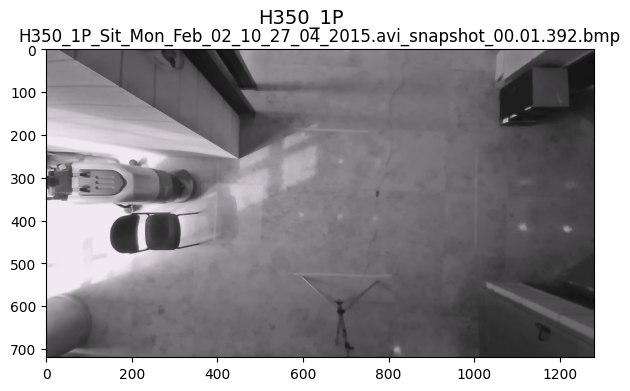

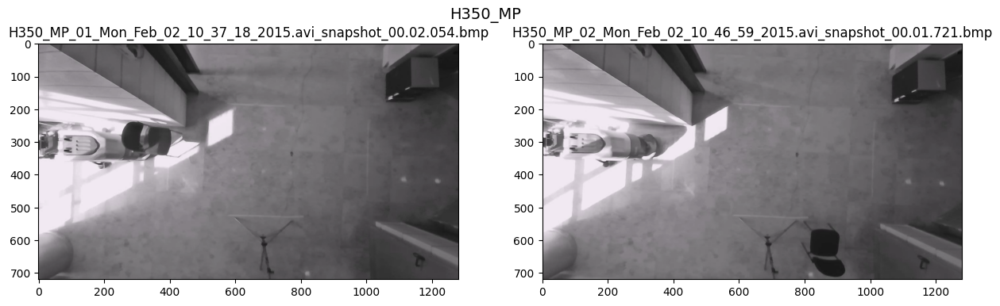

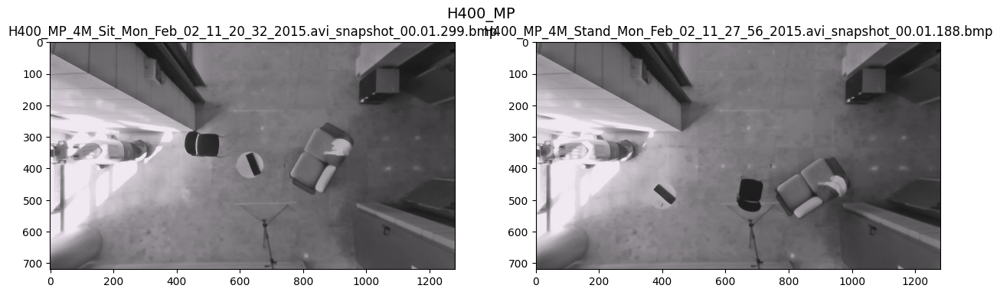

In [94]:
for name in np.array(list(groups.keys()))[connected_components[6]]:
    draw_group(groups[name], name)

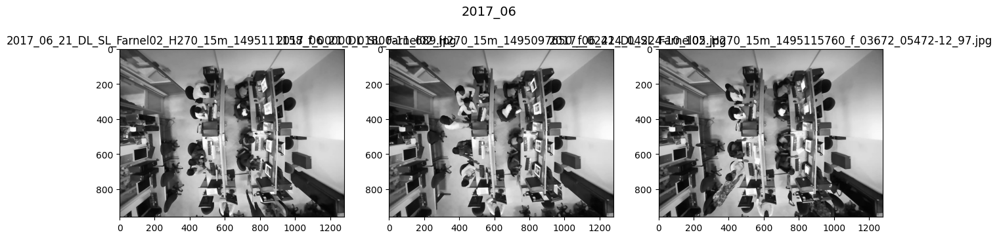

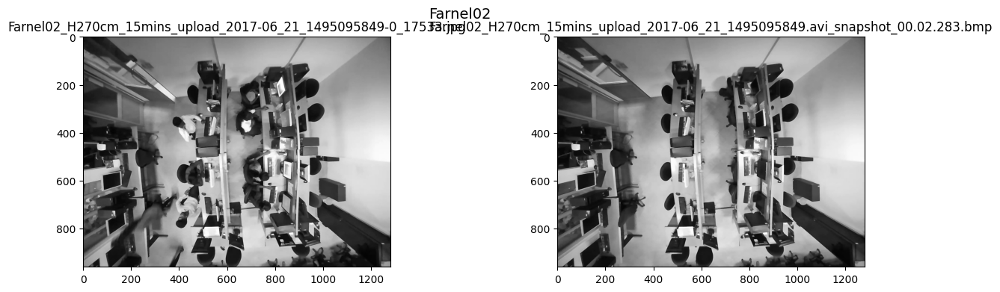

In [95]:
for name in np.array(list(groups.keys()))[connected_components[7]]:
    draw_group(groups[name], name)

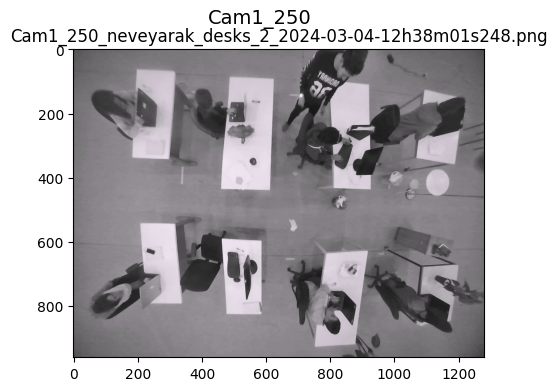

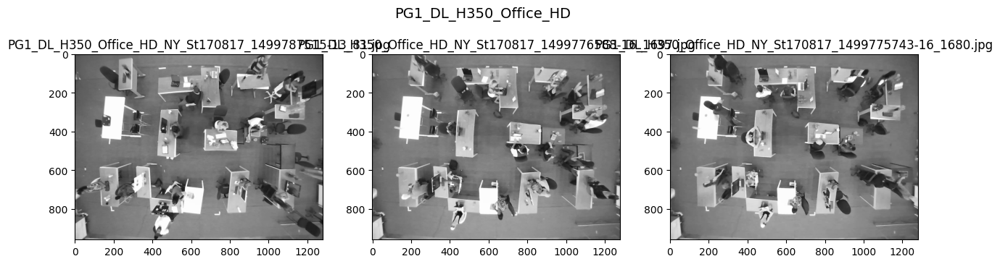

In [96]:
for name in np.array(list(groups.keys()))[connected_components[8]]:
    draw_group(groups[name], name)